# Partículas — boletín III

### Interacción con la materia, detectores y del dato al resultado

Jose A. Hernando

*Departamento de Física de Partículas. Universidade de Santiago de Compostela*

Curso 2026/27

In [1]:
# Configuración e imports
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Paleta Okabe-Ito (apta para daltónicos)
C_SIG, C_BKG = '#0072B2', '#E69F00'

## Contenido

Soluciones del boletín III del curso 2026/27, con la misma numeración que el boletín en pdf. Los ejercicios
recorren la parte experimental del capítulo de perspectivas:

* **Interacción con la materia.** 1 — La sección eficaz $\pi^+ + p$. 2 — Muones en la roca.
* **Detectores.** 3 — Tiempo de vuelo. 4 — La sagitta.
* **Del dato al resultado.** 5 — Eficiencia de un trigger de dos muones. 6 — Neutrinos de reactor: Poisson y
  Bayes. 7 — La sección eficaz $e^+ + e \to \pi^+ + \pi^-$.
* **Aceleradores.** 8 — La luminosidad de un colisionador.

**Notación.** Unidades naturales, $\hbar = c = 1$, salvo que se indique lo contrario. $1$ mb $= 10^{-27}$ cm$^2$,
$1$ nb $= 10^{-33}$ cm$^2$, $1$ GeV$^{-2} = 3.8938\cdot10^{5}$ nb. $N_A = 6.022\cdot10^{23}$ mol$^{-1}$,
$m_{\pi^\pm} = 139.57$ MeV, $m_K = 493.7$ MeV.

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 1 — La sección eficaz $\pi^+ + p$</b></p>

Para medir la sección eficaz de la interacción $\pi^+ + p$ enviamos un haz de $\pi^+$ de $20$ GeV de energía a un
tanque de longitud $L = 1$ m, que en una primera configuración está vacío y luego lleno de hidrógeno líquido, y
medimos los flujos tras el tanque normalizados al mismo flujo incidente y obtenemos $N_0 = 7.5\cdot10^5$ y
$N_H = 6.9\cdot10^5$. Calcula la sección eficaz y su error estadístico.

Datos: $\rho_H = 60$ kg/m$^3$.

</div>

In [2]:
NA = 6.022e23
N0, NH, L = 7.5e5, 6.9e5, 100.0          # cm
n = 0.060 * NA / 1.0                     # protones/cm^3 (rho = 0.060 g/cm^3, A = 1 g/mol)
sigma  = -np.log(NH / N0) / (n * L)
dsigma = np.sqrt(1 / NH + 1 / N0) / (n * L)
print('n = {:.2e} cm^-3'.format(n))
print('fracción que interacciona = {:.1%}'.format(1 - NH / N0))
print('sigma = ({:.1f} +- {:.1f}) mb'.format(sigma / 1e-27, dsigma / 1e-27))

n = 3.61e+22 cm^-3
fracción que interacciona = 8.0%
sigma = (23.1 +- 0.5) mb


<details>
<summary><b>Solución</b></summary>

La fracción del haz que atraviesa el blanco sin interaccionar es

$$
\frac{N_H}{N_0} = e^{-n\sigma L}
\quad\Rightarrow\quad
\sigma = -\frac{1}{nL}\ln\frac{N_H}{N_0},
$$

con $n$ la densidad de protones del blanco. Con $\rho_H = 60$ kg/m$^3$ $= 0.060$ g/cm$^3$ y $A_H \simeq 1$ g/mol,
$n = \rho_H N_A/A_H = 3.61\cdot10^{22}$ cm$^{-3}$, y con $L = 100$ cm:

$$
\sigma = 2.31\cdot10^{-26}\ \text{cm}^2 = 23.1\ \text{mb}.
$$

**Error estadístico.** $N_0$ y $N_H$ son de Poisson, $\delta N = \sqrt N$. Como
$\sigma = (\ln N_0 - \ln N_H)/(nL)$,

$$
\delta\sigma = \frac{1}{nL}\sqrt{\frac{1}{N_H} + \frac{1}{N_0}} = 0.46\ \text{mb},
\qquad
\sigma = (23.1 \pm 0.5)\ \text{mb}.
$$

Solo interacciona un $8\,\%$ del haz: el blanco es «delgado», y el error lo dominan las fluctuaciones de dos
números grandes casi iguales. El valor es el de la sección eficaz total $\pi^+ + p$ a esa energía. (La densidad
real del hidrógeno líquido es $71$ kg/m$^3$; con ella saldría $19.6$ mb.)

</details>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 2 — Muones en la roca</b></p>

Los muones de alta energía pierden energía atravesando la materia según

$$
-\frac{1}{\rho}\frac{\mathrm{d}E}{\mathrm{d}x} \simeq a + bE,
$$

donde $a \simeq 2.5$ MeV cm$^2$/g está asociado a la pérdida por ionización y $b \simeq 3.5\cdot10^{-6}$ cm$^2$/g
a la radiación de frenado para roca. Considerar $A = 22$, $Z = 11$ y $\rho = 2.65$ g/cm$^3$.

(a) ¿A qué energía la pérdida de energía por ionización es igual a la pérdida por *bremsstrahlung*?
(b) ¿Cuánta distancia recorre en promedio un muón cósmico de $100$ GeV en roca?

</div>

E_c = 714 GeV
X = 3.74e+04 g/cm^2  ->  R = 141 m   (solo ionización: 151 m)


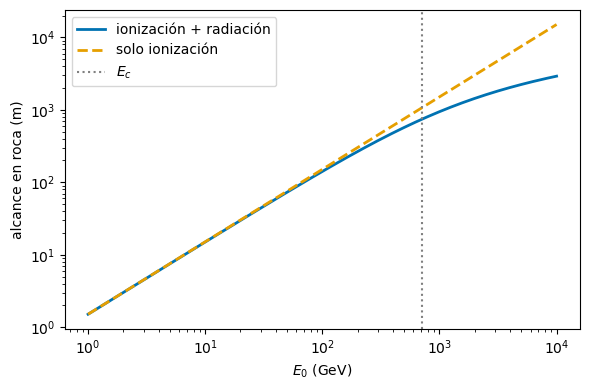

In [3]:
a, b, rho = 2.5, 3.5e-6, 2.65            # MeV cm^2/g, cm^2/g, g/cm^3
E0 = 1e5                                 # MeV
Ec = a / b
X  = np.log(1 + b * E0 / a) / b          # g/cm^2
print('E_c = {:.0f} GeV'.format(Ec / 1e3))
print('X = {:.2e} g/cm^2  ->  R = {:.0f} m   (solo ionización: {:.0f} m)'.format(X, X / rho / 100, E0 / a / rho / 100))

# alcance en función de la energía inicial
E = np.logspace(3, 7, 200)               # MeV
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(E / 1e3, np.log(1 + b * E / a) / b / rho / 100, color=C_SIG, lw=2, label='ionización + radiación')
ax.loglog(E / 1e3, E / a / rho / 100, color=C_BKG, ls='--', lw=2, label='solo ionización')
ax.axvline(Ec / 1e3, color='gray', ls=':', label='$E_c$')
ax.set_xlabel('$E_0$ (GeV)'); ax.set_ylabel('alcance en roca (m)'); ax.legend(); plt.tight_layout()

<details>
<summary><b>Solución</b></summary>

**(a)** La ionización es $\propto a$ y la radiación $\propto bE$; se igualan en la **energía crítica**

$$
E_c = \frac{a}{b} = \frac{2.5}{3.5\cdot10^{-6}}\ \text{MeV} \simeq 714\ \text{GeV}.
$$

Por debajo domina la ionización; por encima, la pérdida radiativa. Es mucho mayor que la del electrón
($E_c \simeq 610\ \text{MeV}/(Z+1.24) \simeq 50$ MeV en roca) porque la radiación va como $1/m^2$.

**(b)** Con $\mathrm{d}E/\mathrm{d}x = -\rho(a + bE)$, separando variables e integrando hasta $E \simeq 0$:

$$
R = \frac{1}{\rho b}\ln\left(\frac{a + bE_0}{a}\right),
\qquad
X = \rho R = \frac{1}{b}\ln\left(1 + \frac{bE_0}{a}\right).
$$

Con $E_0 = 10^5$ MeV, $bE_0 = 0.35$ MeV cm$^2$/g y $X \simeq 3.74\cdot10^{4}$ g/cm$^2$, luego
$R = X/\rho \simeq 1.41\cdot10^{4}$ cm $\simeq 141$ m. Solo con ionización serían $E_0/(\rho a) \simeq 151$ m: a
$100$ GeV la radiación apenas cuenta. Por eso los laboratorios subterráneos se miden en «metros equivalentes de
agua» y necesitan cientos de metros de roca para frenar los muones cósmicos.

</details>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 3 — Tiempo de vuelo</b></p>

Un sistema de tiempo de vuelo (TOF) consta de dos centelleadores separados una distancia $L$, que las partículas
atraviesan perpendicularmente; para cada partícula se mide el tiempo que tarda en ir del primero al segundo.

(a) Considera dos partículas de masas $m_1$, $m_2$ con el mismo momento $p$: ¿cuál es la diferencia entre sus
tiempos de vuelo?
(b) Si la resolución temporal de cada centelleador es de $300$ ps, ¿a qué distancia deben estar situados para
separar $\pi$ de $K$ de $4$ GeV de momento a $3$ desviaciones estándar?
(c) En un colisionador como el LHC, el instante de producción $t_0$ se conoce con precisión a partir del cruce de
los haces y del vértice de la colisión, y basta entonces con un único centelleador situado a una distancia $L$ del
punto de interacción. ¿A qué distancia debería estar para la misma separación? Supón despreciable la incertidumbre
en $t_0$.

</div>

Delta t / L = 23.3 ps/m
dos centelleadores    : sigma = 424 ps  ->  L = 55 m
un centelleador + t0  : sigma = 300 ps  ->  L = 39 m


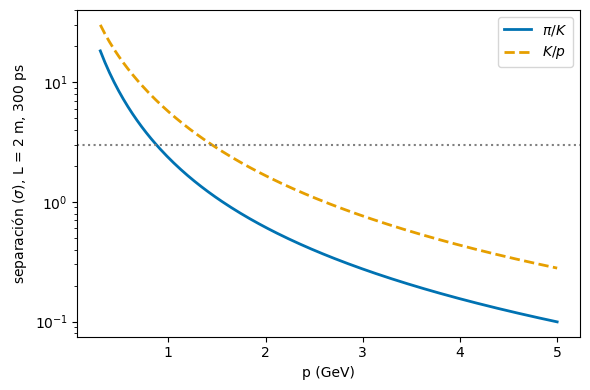

In [4]:
c_m_ps = 3.0e8 * 1e-12                   # m/ps
m_pi, m_K, p = 0.13957, 0.4937, 4.0      # GeV
beta = lambda m, p: p / np.sqrt(p**2 + m**2)
dt_L = (1 / beta(m_K, p) - 1 / beta(m_pi, p)) / c_m_ps          # ps/m
print('Delta t / L = {:.1f} ps/m'.format(dt_L))
for nombre, sig_t in (('dos centelleadores', np.hypot(300, 300)), ('un centelleador + t0', 300.0)):
    print('{:22s}: sigma = {:.0f} ps  ->  L = {:.0f} m'.format(nombre, sig_t, 3 * sig_t / dt_L))

# separación en sigmas para L = 2 m (un TOF real) en función del momento
pp = np.linspace(0.3, 5, 200)
fig, ax = plt.subplots(figsize=(6, 4))
for (m1, m2, lab, col, ls) in ((m_pi, m_K, r'$\pi/K$', C_SIG, '-'), (m_K, 0.93827, r'$K/p$', C_BKG, '--')):
    ax.plot(pp, (1 / beta(m2, pp) - 1 / beta(m1, pp)) * 2.0 / c_m_ps / 300, color=col, ls=ls, lw=2, label=lab)
ax.axhline(3, color='gray', ls=':')
ax.set_yscale('log'); ax.set_xlabel('p (GeV)'); ax.set_ylabel(r'separación ($\sigma$), L = 2 m, 300 ps')
ax.legend(); plt.tight_layout()

<details>
<summary><b>Solución</b></summary>

**(a)** $\beta = p/E = p/\sqrt{p^2 + m^2}$ y $t = L/(\beta c)$:

$$
\Delta t = \frac{L}{c}\left(\frac{1}{\beta_1} - \frac{1}{\beta_2}\right)
= \frac{L}{c}\left(\sqrt{1 + \frac{m_1^2}{p^2}} - \sqrt{1 + \frac{m_2^2}{p^2}}\right)
\simeq \frac{L}{2c}\,\frac{m_1^2 - m_2^2}{p^2}\quad(p \gg m).
$$

**(b)** A $4$ GeV, $\beta_\pi = 0.99939$ y $\beta_K = 0.99245$: $\Delta t/L \simeq 23.3$ ps/m. El tiempo de vuelo
es la diferencia de dos medidas independientes, $\sigma_{\Delta t} = \sqrt2\cdot300 = 424$ ps; a $3\sigma$ hacen
falta $1.27$ ns, es decir, $L \simeq 55$ m. Impracticable: a varios GeV el TOF no separa $\pi$ de $K$, y se usa
el Cherenkov.

**(c)** Con $t_0$ externo, $\sigma = 300$ ps, $3\sigma = 0.90$ ns y $L \simeq 39$ m: un factor $\sqrt2$ menos.
Es la idea de los detectores de tiempo de los experimentos del LHC: el $t_0$ del suceso sustituye al primer
centelleador. La figura muestra que con $L = 2$ m el TOF separa a $3\sigma$ $\pi/K$ hasta $\sim 0.9$ GeV y $K/p$
hasta $\sim 1.5$ GeV: como $\Delta t \propto 1/p^2$, es una técnica de bajo momento.

</details>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 4 — La sagitta</b></p>

Considera un espectrómetro de longitud $L$ y campo magnético $B$ y tres cámaras de detección situadas antes, en
el medio y después del espectrómetro, que nos permiten estimar la *sagitta*

$$
s = x_2 - \frac{x_3 + x_1}{2}.
$$

Calcula el momento transverso de la partícula y su incertidumbre si la resolución de cada cámara es $\sigma_x$.
Considerar $\theta$ pequeño (ver la figura).

<img src="../imgs/bol3_sagitta.png" width=420>

</div>

In [5]:
def sagitta(pT, B, L):
    # s = L^2/(8R), con R = pT/(0.3 B)   [GeV, T, m]
    return L**2 * 0.3 * B / (8 * pT)

B, L, sx = 1.0, 1.0, 100e-6              # T, m, m
for pT in (1, 10, 100):
    s = sagitta(pT, B, L)
    print('pT = {:5.0f} GeV:  R = {:6.1f} m,  s = {:7.3f} mm,  sigma_pT/pT = {:5.1%}'.format(
          pT, pT / (0.3 * B), 1e3 * s, np.sqrt(1.5) * sx / s))

pT =     1 GeV:  R =    3.3 m,  s =  37.500 mm,  sigma_pT/pT =  0.3%
pT =    10 GeV:  R =   33.3 m,  s =   3.750 mm,  sigma_pT/pT =  3.3%
pT =   100 GeV:  R =  333.3 m,  s =   0.375 mm,  sigma_pT/pT = 32.7%


<details>
<summary><b>Solución</b></summary>

**Momento y radio.** El campo no hace trabajo: $|\vec p|$ y $\gamma$ son constantes y en el plano perpendicular a
$\vec B$ la trayectoria es una circunferencia. Igualando $p_T v_T/R = q v_T B$, $p_T = qBR$, válido
relativísticamente. En unidades prácticas,

$$
p_T\ [\text{GeV}] = 0.3\, B\ [\text{T}]\; R\ [\text{m}].
$$

**Sagitta y radio.** En el caso simétrico, Pitágoras en el triángulo centro–punto medio de la cuerda–extremo da
$(R-s)^2 + (L/2)^2 = R^2$, y con $s \ll R$, $s \simeq L^2/(8R)$. En general la traza entra inclinada; para
ángulos pequeños el arco es una parábola, $x(z) \simeq K - (z - z_c)^2/(2R)$, y evaluando en $z = 0, L/2, L$ los
términos en $z_c$ se cancelan: $s = L^2/(8R)$ con cualquier inclinación (una inclinación suma un término lineal,
que desplaza igual el arco y la cuerda). Por tanto

$$
p_T = \frac{0.3\,B L^2}{8 s}.
$$

**Incertidumbre.** Como $p_T \propto 1/s$, $\sigma_{p_T}/p_T = \sigma_s/s$. Con tres medidas independientes,
$\sigma_s^2 = \sigma_x^2 + 2(\sigma_x/2)^2 = \tfrac32\sigma_x^2$, y

$$
\frac{\sigma_{p_T}}{p_T} = \sqrt{\frac32}\,\frac{\sigma_x}{s} = \sqrt{\frac32}\,\frac{8\,\sigma_x}{0.3\,BL^2}\;p_T .
$$

La resolución relativa **empeora linealmente con $p_T$**: cuanto más rígida la traza, menor la sagitta. Y mejora
como $BL^2$: es más rentable alargar el espectrómetro que aumentar el campo. Con $B = 1$ T, $L = 1$ m y
$\sigma_x = 100\ \mu$m, un muón de $10$ GeV tiene $s \simeq 3.8$ mm y $\sigma_{p_T}/p_T \simeq 3\,\%$; a $100$ GeV,
un $30\,\%$.

</details>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 5 — Eficiencia de un trigger de dos muones</b></p>

El sistema de disparo de un experimento selecciona un muón con un momento transverso bajo $p_T > 4$ GeV (LPT) u
otro de alto momento con $p_T > 20$ GeV (HPT). La eficiencia para un muón de la desintegración
$Z^0 \to \mu^+ + \mu$ es de $89\,\%$ y $62\,\%$ para LPT y HPT respectivamente. ¿Cuál sería la eficiencia para un
disparo basado en los dos muones del $Z^0$ con las siguientes configuraciones?

(a) LPT1 y LPT2. (b) HPT1 o HPT2.

</div>

In [6]:
# eficiencias por suceso con dos muones independientes
e_lpt, e_hpt = 0.89, 0.62
print('(a) LPT1 y LPT2: {:.1%}'.format(e_lpt**2))
print('(b) HPT1 o HPT2: {:.1%}'.format(1 - (1 - e_hpt)**2))

(a) LPT1 y LPT2: 79.2%
(b) HPT1 o HPT2: 85.6%


<details>
<summary><b>Solución</b></summary>

Suponemos que las eficiencias de los dos muones son independientes.

**(a)** «Y»: los dos muones tienen que pasar el corte LPT, $\varepsilon = \varepsilon^2_{LPT} = 0.89^2 \simeq
79\,\%$.

**(b)** «O»: basta con uno. Es más sencillo calcular el complementario, que no pase ninguno:
$\varepsilon = 1 - (1 - \varepsilon_{HPT})^2 = 1 - 0.38^2 \simeq 86\,\%$.

Pedir los dos muones cuesta eficiencia; aceptar cualquiera de los dos la recupera, aunque el corte por muón sea
más duro. La independencia es una hipótesis: los dos muones salen de la misma desintegración, y si, por ejemplo,
el $Z^0$ se produce con poco momento transverso, los dos tienen un $p_T$ parecido y pasan o fallan el corte a la vez.

</details>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 6 — Neutrinos de reactor: Poisson y Bayes</b></p>

Un experimento de neutrinos opera cerca de una central nuclear. La estimación del experimento es que interaccionan
$1.2$ neutrinos al día provenientes de la central y que la eficiencia de detección es del $62\,\%$.

Primero operaron el detector mientras la central permaneció parada durante $50$ días y observaron $3$ sucesos
similares a los esperados.

(a) ¿Qué probabilidad hay de que cuando la central entre en funcionamiento observe al menos $1$ suceso el primer
día?
(b) Si se observa un suceso, ¿cuál es la probabilidad de que sea espurio?

</div>

In [7]:
lam_S = 1.2 * 0.62                       # sucesos/día de la central
lam_B = 3 / 50                           # sucesos/día de fondo
lam   = lam_S + lam_B
print('lambda_S = {:.3f}, lambda_B = {:.3f}, lambda = {:.3f} por día'.format(lam_S, lam_B, lam))
print('(a) P(N >= 1) = {:.1%}'.format(1 - stats.poisson.pmf(0, lam)))

# (b) Bayes: P(fondo | N=1) = P(N=1 | fondo) P(fondo) / P(N=1)
p1  = stats.poisson.pmf(1, lam)
pB1 = stats.poisson.pmf(1, lam_B) * stats.poisson.pmf(0, lam_S) / p1
print('(b) P(espurio | N = 1) = {:.1%}   (= lambda_B/lambda = {:.1%})'.format(pB1, lam_B / lam))

# el fondo se conoce solo con 3 sucesos: lambda_B = (3 +- sqrt(3))/50
for lb in ((3 - np.sqrt(3)) / 50, (3 + np.sqrt(3)) / 50):
    print('    lambda_B = {:.3f}: {:.1%}'.format(lb, lb / (lam_S + lb)))

lambda_S = 0.744, lambda_B = 0.060, lambda = 0.804 por día
(a) P(N >= 1) = 55.2%
(b) P(espurio | N = 1) = 7.5%   (= lambda_B/lambda = 7.5%)
    lambda_B = 0.025: 3.3%
    lambda_B = 0.095: 11.3%


<details>
<summary><b>Solución</b></summary>

Los sucesos de la central y los de fondo son de Poisson, con $\lambda_S = 1.2 \cdot 0.62 = 0.744$ y
$\lambda_B = 3/50 = 0.060$ sucesos al día; los $3$ sucesos con la central parada miden el fondo.

**(a)** Con la central en marcha, $\lambda = \lambda_S + \lambda_B = 0.804$, y

$$
P(N \ge 1) = 1 - P(N = 0) = 1 - e^{-\lambda} \simeq 55\,\%.
$$

**(b)** Entendemos que el primer día se observa exactamente un suceso, $N = 1$, y queremos la probabilidad de que
sea de fondo (y ninguno de la central). Por el teorema de Bayes, $P(A\,|\,B)\,P(B) = P(B\,|\,A)\,P(A)$:

$$
P(\text{fondo}\,|\,N=1) = \frac{P(N=1\,|\,\text{fondo})\,P(\text{fondo})}{P(N=1)}
= \frac{1\cdot\lambda_B e^{-\lambda_B}\,e^{-\lambda_S}}{\lambda e^{-\lambda}}
= \frac{\lambda_B}{\lambda_B + \lambda_S} \simeq 7.5\,\%.
$$

$P(\text{fondo}) = P(N_B = 1)\,P(N_S = 0)$ porque fondo y señal son independientes, y $P(N=1)$ es Poisson de media
$\lambda$ (la suma de dos Poisson es Poisson). Las exponenciales se cancelan: con un solo suceso, la probabilidad
de que venga de cada fuente es proporcional a su tasa. El fondo es $12$ veces menos frecuente que la señal, y solo
$1$ de cada $\sim 13$ sucesos aislados es espurio.

El resultado supone que el fondo medido con la central parada es el mismo con la central en marcha, y está mal
conocido: con $3$ sucesos, $\lambda_B = (0.060 \pm 0.035)$ por día, y la probabilidad de (b) está entre un $3$ y
un $11\,\%$.

</details>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 7 — La sección eficaz $e^+ + e \to \pi^+ + \pi^-$</b></p>

Estima la sección eficaz (y sus errores estadísticos y sistemáticos) de $e^+ + e \to \pi^+ + \pi^-$ a
$\sqrt{s} = 1$ GeV con los datos que obtuvo el siguiente experimento: con una luminosidad integrada de
$\mathcal{L}_{int} = 2.43$ nb$^{-1}$ se observaron $128$ sucesos candidatos, la eficiencia de selección se estimó en
$\varepsilon = (52 \pm 0.2)\,\%$ y el fondo de contaminación en $N_B = 14 \pm 1.8$ sucesos.

La sección eficaz se espera teóricamente que sea

$$
\sigma(s) = \frac{\pi\alpha^2}{s}\,\beta_\pi^3\,|F(s)|^2,
$$

donde $\beta_\pi$ es la velocidad del pión en unidades de $c$, $\alpha$ la constante de estructura fina y $F(s)$ un
factor teórico. ¿Puedes estimar el valor y la incertidumbre de $|F(s)|$ a partir de las medidas del experimento?

</div>

In [8]:
Lint, Nobs, NB, dNB, eps, deps = 2.43, 128, 14, 1.8, 0.52, 0.002    # nb^-1, sucesos, -, -
sig  = (Nobs - NB) / (Lint * eps)
dst  = np.sqrt(Nobs) / (Lint * eps)
dsy  = np.hypot(dNB / (Lint * eps), sig * deps / eps)
print('sigma = ({:.1f} +- {:.1f} stat +- {:.1f} sist) nb'.format(sig, dst, dsy))

s, alpha, GeV2nb = 1.0, 1 / 137.036, 3.8938e5                         # GeV^2, -, nb GeV^2
b_pi = np.sqrt(1 - 4 * 0.13957**2 / s)
for nombre, k in (('pi alpha^2/s   (enunciado)', 1), ('pi alpha^2/(3s) (correcta) ', 3)):
    F = np.sqrt(k * sig / GeV2nb * s / (np.pi * alpha**2 * b_pi**3))
    print('{}:  |F| = {:.2f} +- {:.2f} stat +- {:.3f} sist,  |F|^2 = {:.1f}'.format(
          nombre, F, F * dst / sig / 2, F * dsy / sig / 2, F**2))
print('beta_pi = {:.4f}'.format(b_pi))

sigma = (90.2 +- 9.0 stat +- 1.5 sist) nb
pi alpha^2/s   (enunciado):  |F| = 1.25 +- 0.06 stat +- 0.010 sist,  |F|^2 = 1.6
pi alpha^2/(3s) (correcta) :  |F| = 2.17 +- 0.11 stat +- 0.018 sist,  |F|^2 = 4.7
beta_pi = 0.9603


<details>
<summary><b>Solución</b></summary>

**Sección eficaz.** $N_S = N_{obs} - N_B = 114$ y $N_S = \sigma\,\mathcal{L}_{int}\,\varepsilon$, luego
$\sigma = 114/(2.43 \cdot 0.52) = 90.2$ nb.

* **Estadístico:** Poisson del número observado, $\delta\sigma_{stat} = \sqrt{128}/(\mathcal{L}_{int}\varepsilon)
  = 9.0$ nb.
* **Sistemático:** del fondo, $1.8/(\mathcal{L}_{int}\varepsilon) = 1.42$ nb; de la eficiencia,
  $\sigma\,\delta\varepsilon/\varepsilon = 90.2 \cdot 0.2/52 = 0.35$ nb; en cuadratura, $1.5$ nb.

$$
\sigma = (90.2 \pm 9.0_{stat} \pm 1.5_{sist})\ \text{nb}.
$$

Domina el error estadístico: con $128$ sucesos, un $9\,\%$ relativo ($\sqrt{128}/114$, porque el fondo también
fluctúa).

**Factor de forma.** En un colisionador simétrico el centro de masas es el laboratorio y cada pión lleva
$E_\pi = \sqrt s/2$, así que $\beta_\pi = \sqrt{1 - 4m_\pi^2/s} = 0.960$. El factor $\beta_\pi^3$ tiene dos
orígenes: un $\beta_\pi$ del espacio fásico y $\beta_\pi^2$ de que dos piones sin espín producidos por un fotón
virtual (espín 1) salen en onda P ($L = 1$). Despejando, con $1$ GeV$^{-2} = 3.8938\cdot10^5$ nb y
$\alpha = 1/137.036$,

$$
|F(s)| = \sqrt{\frac{\sigma s}{\pi\alpha^2\beta_\pi^3}} \simeq 1.25 .
$$

Como $|F| \propto \sqrt\sigma$, $\delta F/F = \tfrac12\,\delta\sigma/\sigma$:

$$
|F(s)| = 1.25 \pm 0.06_{stat} \pm 0.01_{sist}.
$$

</details>

<div class="admonition warning">
<p class="admonition-title"><b>Errata: falta un 1/3 en la fórmula</b></p>

La sección eficaz de $e^+ + e \to \pi^+ + \pi^-$ es

$$
\sigma(s) = \frac{\pi\alpha^2}{3s}\,\beta_\pi^3\,|F(s)|^2 .
$$

La onda P da $\mathrm{d}\sigma/\mathrm{d}\Omega \propto \sin^2\theta$, y al integrar aparece el $1/3$ frente a
$\sigma(e^+ + e \to \mu^+ + \mu) = 4\pi\alpha^2/(3s)$, que va como $1 + \cos^2\theta$. Con la fórmula correcta,
$|F| = \sqrt{3}\cdot1.25 \simeq 2.17 \pm 0.11_{stat} \pm 0.02_{sist}$ y $|F|^2 \simeq 4.7$. $F$ es el **factor de
forma** del pión: un pión puntual tendría $|F| = 1$, y $|F|^2 \simeq 4.7$ refleja su estructura, la cola de la
resonancia $\rho$ ($m_\rho = 775$ MeV), que domina la producción de dos piones a estas energías.

Una eficiencia conocida al $0.2\,\%$ absoluto ($0.4\,\%$ relativo) es muy optimista; un $\pm 2\,\%$ sería más
realista, y el sistemático subiría a $3.8$ nb, aún por debajo del estadístico.

</div>

<div class="admonition tip">
<p class="admonition-title"><b>[>] Ejercicio 8 — La luminosidad de un colisionador</b></p>

Sea un colisionador donde $n$ paquetes que contienen $N$ partículas recorren un anillo con una frecuencia $\nu$ en
los dos sentidos. Al colisionar se reducen los paquetes a una sección transversal de radio $\sigma$. ¿Cuál es la
luminosidad del colisionador?

</div>

In [9]:
# Ejemplo numérico: LHC con los parámetros de diseño
n, N, nu, sig = 2808, 1.15e11, 11.245e3, 16.7e-4     # paquetes, protones/paquete, Hz, cm
L_unif  = n * N**2 * nu / (np.pi * sig**2)
L_gauss = n * N**2 * nu / (4 * np.pi * sig**2)
print('L (disco uniforme) = {:.1e} cm^-2 s^-1'.format(L_unif))
print('L (gaussiana)      = {:.1e} cm^-2 s^-1'.format(L_gauss))

L (disco uniforme) = 4.8e+34 cm^-2 s^-1
L (gaussiana)      = 1.2e+34 cm^-2 s^-1


<details>
<summary><b>Solución</b></summary>

$\mathcal{L}$ se define de forma que la tasa de un proceso de sección eficaz $\sigma_{int}$ sea
$R = \sigma_{int}\mathcal{L}$.

* **Un cruce.** Las $N$ partículas de un paquete se reparten uniformemente sobre el área $A = \pi\sigma^2$; una
  partícula del otro paquete interacciona con probabilidad $N\sigma_{int}/A$ (la fracción del área cubierta por
  los $N$ «discos» $\sigma_{int}$). Con $N$ partículas en el paquete que llega, $N_{int} = N^2\sigma_{int}/A$.
* **Cruces por segundo.** Cada paquete pasa $\nu$ veces por segundo por el punto de interacción; con $n$ paquetes
  por haz, hay $n\nu$ cruces por segundo.

$$
R = n\nu\,\frac{N^2}{A}\,\sigma_{int}
\quad\Rightarrow\quad
\mathcal{L} = \frac{n N^2 \nu}{\pi\sigma^2}.
$$

En los aceleradores reales la distribución transversal es gaussiana, de anchura $\sigma$ en $x$ e $y$, y el área
efectiva es la integral de solapamiento, $1/A = \int\rho_1\rho_2\,\mathrm{d}x\,\mathrm{d}y = 1/(4\pi\sigma^2)$:
$\mathcal{L} = nN^2\nu/(4\pi\sigma^2)$, la fórmula habitual. En los dos casos $\mathcal{L} \propto nN^2\nu/\sigma^2$:
$N^2$ porque interaccionan dos poblaciones, $1/\sigma^2$ porque apretar los haces concentra los blancos. En el LHC
($n = 2808$, $N = 1.15\cdot10^{11}$, $\nu = 11.2$ kHz, $\sigma = 16.7\ \mu$m) la fórmula gaussiana da
$\simeq 1.2\cdot10^{34}$ cm$^{-2}$s$^{-1}$, la luminosidad de diseño.

</details>